### Exercise 1

Take a DNA sequence from NCBI (an entire genome) and take 2000 random samples of about 100-120 bases from it; store these samples in a list.
Rebuild the DNA sequence using these random samples and find out what the main problem will be without the algorithmic approach.

Genome used: *Enterobacteria phage lambda*, complete genome (NCBI **NC_001416.1**, 48,502 bp).

In [1]:
import random

import matplotlib.pyplot as plt


def read_fasta(path):
    """Return the sequence from a FASTA file (header lines starting with '>' are skipped)."""
    with open(path) as f:
        return "".join(line.strip() for line in f if not line.startswith(">")).upper()


def take_samples(genome, n=2000, min_len=100, max_len=120, seed=42):
    """Cut n random fragments (reads) of 100-120 bases out of the genome.
    The start positions are kept only to check the result later - the rebuild does not use them."""
    rng = random.Random(seed)
    samples, starts = [], []
    for _ in range(n):
        length = rng.randint(min_len, max_len)
        start = rng.randint(0, len(genome) - length)
        samples.append(genome[start:start + length])
        starts.append(start)
    return samples, starts


genome = read_fasta("lambda_phage.fasta")
samples, starts = take_samples(genome)

total_bases = sum(len(s) for s in samples)
print("Genome: Enterobacteria phage lambda (NC_001416.1)")
print(f"Genome length   = {len(genome):,} bases")
print(f"Samples         = {len(samples):,} (lengths {min(map(len, samples))}-{max(map(len, samples))})")
print(f"Bases in samples = {total_bases:,}  ->  average coverage = {total_bases / len(genome):.2f}x")
print()
for i in range(3):
    print(f"sample {i}: {samples[i][:60]}...")

Genome: Enterobacteria phage lambda (NC_001416.1)
Genome length   = 48,502 bases
Samples         = 2,000 (lengths 100-120)
Bases in samples = 220,554  ->  average coverage = 4.55x

sample 0: CCGTGTGGCAGAGCTGAAAGAGGAGCTTGATGACACGGATGAAACTGCCGGTCAGGACAC...
sample 1: AACGCCAGCAGACTGGAGGAGTTTTCGAAAGAGTGGAAGGATGCCAGTGATAAGTGGAAT...
sample 2: GTTGTCAGCGGCACAGCCGGGCGATGTGCTGCTGTGCTGTTTTGGTTCATCAGTGCCGAA...


#### Attempt 1: rebuild without any algorithm

The simplest idea is to put the samples back together one after another, in the order we have them.

In [2]:
naive = "".join(samples)

print(f"Rebuilt length  = {len(naive):,} bases (original: {len(genome):,})")
print(f"Identical to the genome: {naive == genome}")

# How many of the joints between two consecutive samples are real neighbours in the genome?
correct_joins = sum(1 for a, b in zip(samples, samples[1:]) if a + b[:20] in genome)
print(f"Correct joints  = {correct_joins} / {len(samples) - 1}")

Rebuilt length  = 220,554 bases (original: 48,502)
Identical to the genome: False
Correct joints  = 0 / 1999


The result is about 4.5 times longer than the genome and is nonsense: the samples are random, so we do not know
where each one came from, they overlap each other, and many regions appear several times.
To rebuild the genome we have to use the only information the samples carry: **overlaps** between them.

#### Attempt 2: greedy overlap merging

1. remove duplicate samples and samples contained inside another sample;
2. for every pair (A, B) find the longest suffix of A that equals a prefix of B (at least 20 bases);
3. repeatedly join the pair with the largest overlap, until no join is possible.

In [3]:
MIN_OVERLAP = 20


def remove_contained(reads):
    """Drop duplicates and reads that appear entirely inside a longer read."""
    unique = sorted(set(reads), key=len, reverse=True)
    kept = []
    for r in unique:
        if not any(r in k for k in kept):
            kept.append(r)
    return kept


def overlap(a, b, min_len=MIN_OVERLAP):
    """Length of the longest suffix of a that is a prefix of b (0 if shorter than min_len)."""
    start = 0
    while True:
        start = a.find(b[:min_len], start)
        if start == -1:
            return 0
        if b.startswith(a[start:]):
            return len(a) - start
        start += 1


def greedy_assemble(reads):
    """Join reads on their largest overlaps first; return the resulting contigs and the comparisons made."""
    reads = remove_contained(reads)
    edges = []
    comparisons = 0
    for i, a in enumerate(reads):
        for j, b in enumerate(reads):
            if i != j:
                comparisons += 1
                o = overlap(a, b)
                if o:
                    edges.append((o, i, j))
    edges.sort(reverse=True)

    nxt, prv = {}, {}

    def first(i):
        while i in prv:
            i = prv[i]
        return i

    for o, i, j in edges:
        # each read can have one successor and one predecessor, and we must not close a cycle
        if i in nxt or j in prv or first(i) == j:
            continue
        nxt[i], prv[j] = (j, o), i

    contigs = []
    for i in range(len(reads)):
        if i in prv:
            continue
        seq = reads[i]
        while i in nxt:
            j, o = nxt[i]
            seq += reads[j][o:]
            i = j
        contigs.append(seq)
    return sorted(contigs, key=len, reverse=True), len(reads), comparisons


contigs, n_reads, comparisons = greedy_assemble(samples)

print(f"Reads left after removing duplicates/contained ones = {n_reads:,}")
print(f"Pairwise comparisons made = {comparisons:,}")
print()
print(f"Number of contigs (rebuilt pieces) = {len(contigs)}  (ideal: 1)")
print(f"Longest contig  = {len(contigs[0]):,} bases ({100 * len(contigs[0]) / len(genome):.1f}% of the genome)")
print(f"Total length    = {sum(map(len, contigs)):,} bases (genome: {len(genome):,})")
print(f"Contigs that really occur in the genome = {sum(c in genome for c in contigs)} / {len(contigs)}")
print("Top 10 contig lengths:", [len(c) for c in contigs[:10]])

Reads left after removing duplicates/contained ones = 1,690
Pairwise comparisons made = 2,854,410

Number of contigs (rebuilt pieces) = 44  (ideal: 1)
Longest contig  = 5,695 bases (11.7% of the genome)
Total length    = 48,205 bases (genome: 48,502)
Contigs that really occur in the genome = 44 / 44
Top 10 contig lengths: [5695, 4022, 3158, 2131, 2083, 2065, 1961, 1939, 1584, 1492]


The genome is **not** rebuilt as a single sequence - we get many separate pieces (contigs). Let's see why, by looking at
how many samples cover each position of the genome (here we use the real start positions, which the rebuild never had).

Positions never sampled = 542 (1.12%) in 21 gaps
Gaps (start-end): 0-71, 334-339, 2422-2423, 3243-3295, 4315-4319, 6450-6462, 9326-9363, 11633-11641, 12719-12721, 12824-12857, 18448-18466, 20470-20476, 21359-21376, 21884-21955, 23420-23449, 25686-25725, 25876-25903, 39352-39387, 41389-41401, 42744-42787, 48482-48502


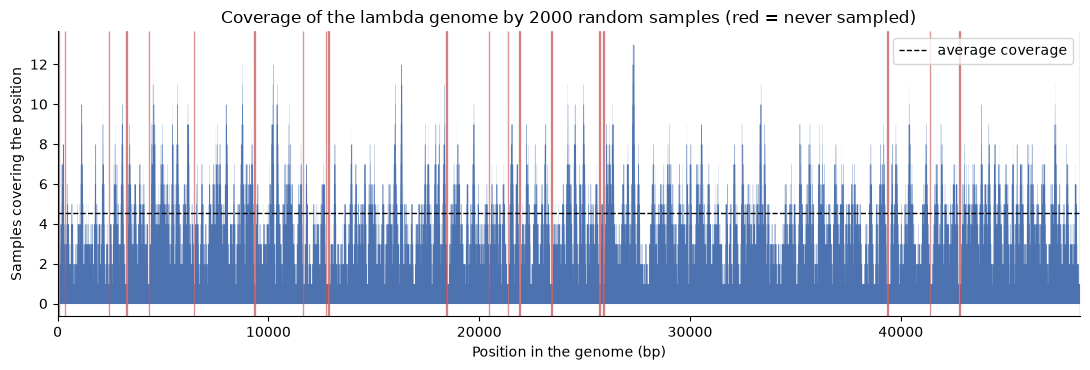

In [4]:
coverage = [0] * len(genome)
for start, s in zip(starts, samples):
    for i in range(start, start + len(s)):
        coverage[i] += 1

# Regions of the genome that no sample touches
gaps, i = [], 0
while i < len(genome):
    if coverage[i] == 0:
        j = i
        while j < len(genome) and coverage[j] == 0:
            j += 1
        gaps.append((i, j))
        i = j
    else:
        i += 1

uncovered = sum(e - s for s, e in gaps)
print(f"Positions never sampled = {uncovered:,} ({100 * uncovered / len(genome):.2f}%) in {len(gaps)} gaps")
print("Gaps (start-end):", ", ".join(f"{s}-{e}" for s, e in gaps))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(range(len(genome)), coverage, step="mid", color="#4C72B0", linewidth=0)
for s, e in gaps:
    ax.axvspan(s, e, color="#C44E52", alpha=0.6)
ax.axhline(total_bases / len(genome), color="black", linestyle="--", linewidth=1, label="average coverage")
ax.set_xlim(0, len(genome))
ax.set_xlabel("Position in the genome (bp)")
ax.set_ylabel("Samples covering the position")
ax.set_title("Coverage of the lambda genome by 2000 random samples (red = never sampled)")
ax.legend(loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#### The repeat problem

Phage lambda has almost no long repeats, so all contigs above are correct. Real genomes (bacteria, humans) have many.
If a region longer than a sample appears twice, the samples from both copies look identical and the merge cannot know
which way to continue. A small example: `UNIQUE_A + REPEAT + UNIQUE_B + REPEAT + UNIQUE_C`.

In [5]:
rng = random.Random(7)
rand_dna = lambda n: "".join(rng.choice("ACGT") for _ in range(n))

A, B, C = rand_dna(1000), rand_dna(1000), rand_dna(1000)
repeat = rand_dna(300)                      # longer than any sample (100-120)
toy = A + repeat + B + repeat + C

toy_samples, _ = take_samples(toy, n=400, seed=6)   # ~13x coverage, so no gaps
toy_contigs, _, _ = greedy_assemble(toy_samples)

print(f"Toy genome = A + REPEAT + B + REPEAT + C, length {len(toy):,} (repeat = {len(repeat)} bases)")
print(f"Contigs = {len(toy_contigs)}, total rebuilt length = {sum(map(len, toy_contigs)):,} (should be {len(toy):,})")
print()
for k, c in enumerate(toy_contigs, 1):
    parts = [name for name, part in (("A", A), ("REPEAT", repeat), ("B", B), ("C", C)) if part[:200] in c or part[-200:] in c]
    print(f"contig {k}: {len(c):,} bases, contains {' + '.join(parts)}  ->  occurs in the genome: {c in toy}")

Toy genome = A + REPEAT + B + REPEAT + C, length 3,600 (repeat = 300 bases)
Contigs = 2, total rebuilt length = 3,483 (should be 3,600)

contig 1: 2,286 bases, contains A + REPEAT + C  ->  occurs in the genome: False
contig 2: 1,197 bases, contains B  ->  occurs in the genome: True


### Conclusion - what is the main problem?

Without an algorithmic approach the genome cannot be rebuilt:

1. **We lose the position of each sample.** Random samples carry no information about where they came from, so simply
   joining them gives a sequence ~4.5x longer than the genome that has nothing to do with it. The only usable
   information is the overlap between samples, and finding it is the whole problem.
2. **Repeats (the main problem).** When a region longer than a sample occurs more than once, samples from different
   copies are identical, so there are several equally good ways to continue. A greedy / brute-force merge either stops
   (more contigs) or joins the wrong pieces and collapses the copies, giving a shorter, wrong genome
   (in the toy example A was glued directly to C and B was cut out as a separate piece). Read length must be longer than the repeats, or extra information is needed.
3. **Gaps from random sampling.** 2000 samples of ~110 bases give only ~4.5x coverage; by chance some regions are never
   sampled (red areas in the plot) and others are covered by reads that overlap too little. The genome comes out in
   many pieces and **their order is unknown**.
4. **Computational cost.** Comparing every sample with every other one is O(n²) (here ~2.8 million comparisons for a
   48 kb virus). For a bacterial genome (millions of reads) or a human genome (hundreds of millions) this brute force
   is impossible, and the greedy choice is not guaranteed to give the shortest/correct sequence
   (shortest common superstring is NP-hard).

That is why real assemblers use smarter algorithms - overlap graphs (OLC) or **De Bruijn graphs** built from k-mers,
high coverage, and paired-end / long reads to cross repeats.